# 01 EDA: Employee Attrition at Next Labs
Goal: understand data shape, cleaning needs, and feature engineering ideas before modeling.
Metric: AUC on the 300-person test set. All EDA conclusions below are drawn from the **training rows only** (`training == 1`) so nothing leaks from the test set.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
DATA_PATH = "..data//EmployeeAttritionPredictionData.xlsx"

## 1. Load data and data dictionary

In [2]:
raw = pd.read_excel(DATA_PATH, sheet_name="Data")
dd = pd.read_excel(DATA_PATH, sheet_name="DataDictionary", header=None, names=["variable", "description"])
dd

,variable,description
0,ID,employee ID
1,Age,NaN
2,Attrition,did employee leave company? 1=yes
3,BusinessTravel,extent of travel
4,Department,NaN
5,DistanceFromHome,distance in miles from office to primary resid...
6,Education,"1=below college, 2=college, 3=bachelor's degre..."
7,Gender,NaN
8,JobLevel,internal classification of level in organizati...
9,JobRole,NaN


In [3]:
df = raw.copy()
df["y"] = (df["Attrition"] == "Yes").astype(int)   # 1 = quit
train = df[df["training"] == 1].copy()
test = df[df["training"] == 0].copy()

print("full :", df.shape)
print("train:", train.shape, "| quit rate:", round(train["y"].mean(), 3), "| quits:", train["y"].sum())
print("test :", test.shape, "| quit rate:", round(test["y"].mean(), 3), "| quits:", test["y"].sum())
df.head()

full : (1470, 22)
train: (1170, 22) | quit rate: 0.158 | quits: 185
test : (300, 22) | quit rate: 0.173 | quits: 52


,ID,Age,Attrition,BusinessTravel,Department,DistanceFromHome,Education,Gender,JobLevel,JobRole,MaritalStatus,MonthlyIncome,NumCompaniesWorked,Overtime,MostRecentPerfEval,TotalWorkingYears,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,training,y
0,100774131,35,No,Travel_Rarely,Research & Development,1,3,Male,1,Research Scientist,Single,2859,1,0,6,6,6,4,0,4,0,0
1,101330756,30,No,Travel_Rarely,Research & Development,8,2,Female,3,Research Director,Married,11416,0,1,5,9,8,7,1,7,1,0
2,101910614,27,Yes,Travel_Frequently,Human Resources,22,3,Female,1,Human Resources,Married,2863,1,0,4,1,1,0,0,0,1,1
3,102548783,39,No,Travel_Rarely,Research & Development,18,2,Male,2,Manufacturing Director,Single,4534,0,0,6,9,8,7,1,7,1,0
4,103053549,36,No,Travel_Rarely,Research & Development,5,2,Male,2,Laboratory Technician,Single,5914,8,0,5,16,13,11,3,7,1,0


## 2. Data shape and quality

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "n_unique": df.nunique(),
})
print("duplicate rows:", df.duplicated().sum(), "| duplicate IDs:", df["ID"].duplicated().sum())
quality

duplicate rows: 0 | duplicate IDs: 0


,dtype,n_missing,n_unique
ID,int64,0,1470
Age,int64,0,43
Attrition,str,0,2
BusinessTravel,str,0,3
Department,str,0,3
DistanceFromHome,int64,0,29
Education,int64,0,5
Gender,str,0,2
JobLevel,int64,0,5
JobRole,str,0,9


In [5]:
num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c not in ["ID", "training", "y"]]
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c]) and c != "Attrition"]
print("numeric    :", num_cols)
print("categorical:", cat_cols)
train[num_cols].describe().T

numeric    : ['Age', 'DistanceFromHome', 'Education', 'JobLevel', 'MonthlyIncome', 'NumCompaniesWorked', 'Overtime', 'MostRecentPerfEval', 'TotalWorkingYears', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
categorical: ['BusinessTravel', 'Department', 'Gender', 'JobRole', 'MaritalStatus']


,count,mean,std,min,25%,50%,75%,max
Age,1170.0,36.864103,9.116459,18.0,30.00,35.0,43.00,60.0
DistanceFromHome,1170.0,9.082906,8.065120,1.0,2.00,7.0,13.00,29.0
Education,1170.0,2.897436,1.022289,1.0,2.00,3.0,4.00,5.0
JobLevel,1170.0,2.081197,1.127192,1.0,1.00,2.0,3.00,5.0
MonthlyIncome,1170.0,6591.442735,4816.260397,1081.0,2935.25,4961.5,8404.25,19999.0
NumCompaniesWorked,1170.0,2.671795,2.483129,0.0,1.00,2.0,4.00,9.0
Overtime,1170.0,0.288034,0.453041,0.0,0.00,0.0,1.00,1.0
MostRecentPerfEval,1170.0,5.572650,2.101839,0.0,4.00,6.0,7.00,10.0
TotalWorkingYears,1170.0,11.377778,7.975745,0.0,6.00,10.0,15.00,40.0
YearsAtCompany,1170.0,7.141880,6.282517,0.0,3.00,5.0,10.00,40.0


### Logical consistency checks
Tenure variables should not exceed total working years or each other.

In [6]:
checks = {
    "YearsAtCompany > TotalWorkingYears": (df["YearsAtCompany"] > df["TotalWorkingYears"]).sum(),
    "YearsInCurrentRole > YearsAtCompany": (df["YearsInCurrentRole"] > df["YearsAtCompany"]).sum(),
    "YearsWithCurrManager > YearsAtCompany": (df["YearsWithCurrManager"] > df["YearsAtCompany"]).sum(),
    "YearsSinceLastPromotion > YearsAtCompany": (df["YearsSinceLastPromotion"] > df["YearsAtCompany"]).sum(),
    "TotalWorkingYears > Age - 14": (df["TotalWorkingYears"] > df["Age"] - 14).sum(),
    "Overtime not in {0,1}": (~df["Overtime"].isin([0, 1])).sum(),
    "MostRecentPerfEval outside 1-10": (~df["MostRecentPerfEval"].between(1, 10)).sum(),
}
pd.Series(checks, name="violations")

YearsAtCompany > TotalWorkingYears          0
YearsInCurrentRole > YearsAtCompany         0
YearsWithCurrManager > YearsAtCompany       0
YearsSinceLastPromotion > YearsAtCompany    0
TotalWorkingYears > Age - 14                0
Overtime not in {0,1}                       0
MostRecentPerfEval outside 1-10             8
Name: violations, dtype: int64

In [7]:
# Department vs JobRole structure (Manager appears in several departments)
pd.crosstab(df["JobRole"], df["Department"])

Department,Human Resources,Research & Development,Sales
JobRole,,,
Healthcare Representative,0,131,0
Human Resources,52,0,0
Laboratory Technician,0,259,0
Manager,11,54,37
Manufacturing Director,0,145,0
Research Director,0,80,0
Research Scientist,0,292,0
Sales Executive,0,0,326
Sales Representative,0,0,83


In [8]:
# Performance eval: the dictionary says 1 to 10, check for out-of-range values
df["MostRecentPerfEval"].value_counts().sort_index()

MostRecentPerfEval
0       8
1      29
2      80
3     127
4     198
5     267
6     261
7     234
8     151
9      73
10     42
Name: count, dtype: int64

## 3. Target and split sanity

In [9]:
split_summary = (df.groupby("training")["y"]
                   .agg(n="size", quits="sum", quit_rate="mean")
                   .rename(index={0: "test", 1: "train"}))
split_summary

,n,quits,quit_rate
training,,,
test,300,52,0.173333
train,1170,185,0.158120


In [10]:
# Does the test set look like the training set? (guards against distribution shift)
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

shift = pd.Series({c: smd(train[c], test[c]) for c in num_cols}, name="std_mean_diff").sort_values(key=abs, ascending=False)
shift.round(3)

YearsAtCompany             0.111
MonthlyIncome              0.095
JobLevel                   0.079
Education                 -0.074
DistanceFromHome          -0.066
TotalWorkingYears          0.064
Overtime                   0.055
YearsWithCurrManager       0.054
YearsInCurrentRole         0.047
NumCompaniesWorked        -0.042
Age                       -0.032
YearsSinceLastPromotion   -0.023
MostRecentPerfEval         0.009
Name: std_mean_diff, dtype: float64

## 4. Numeric features

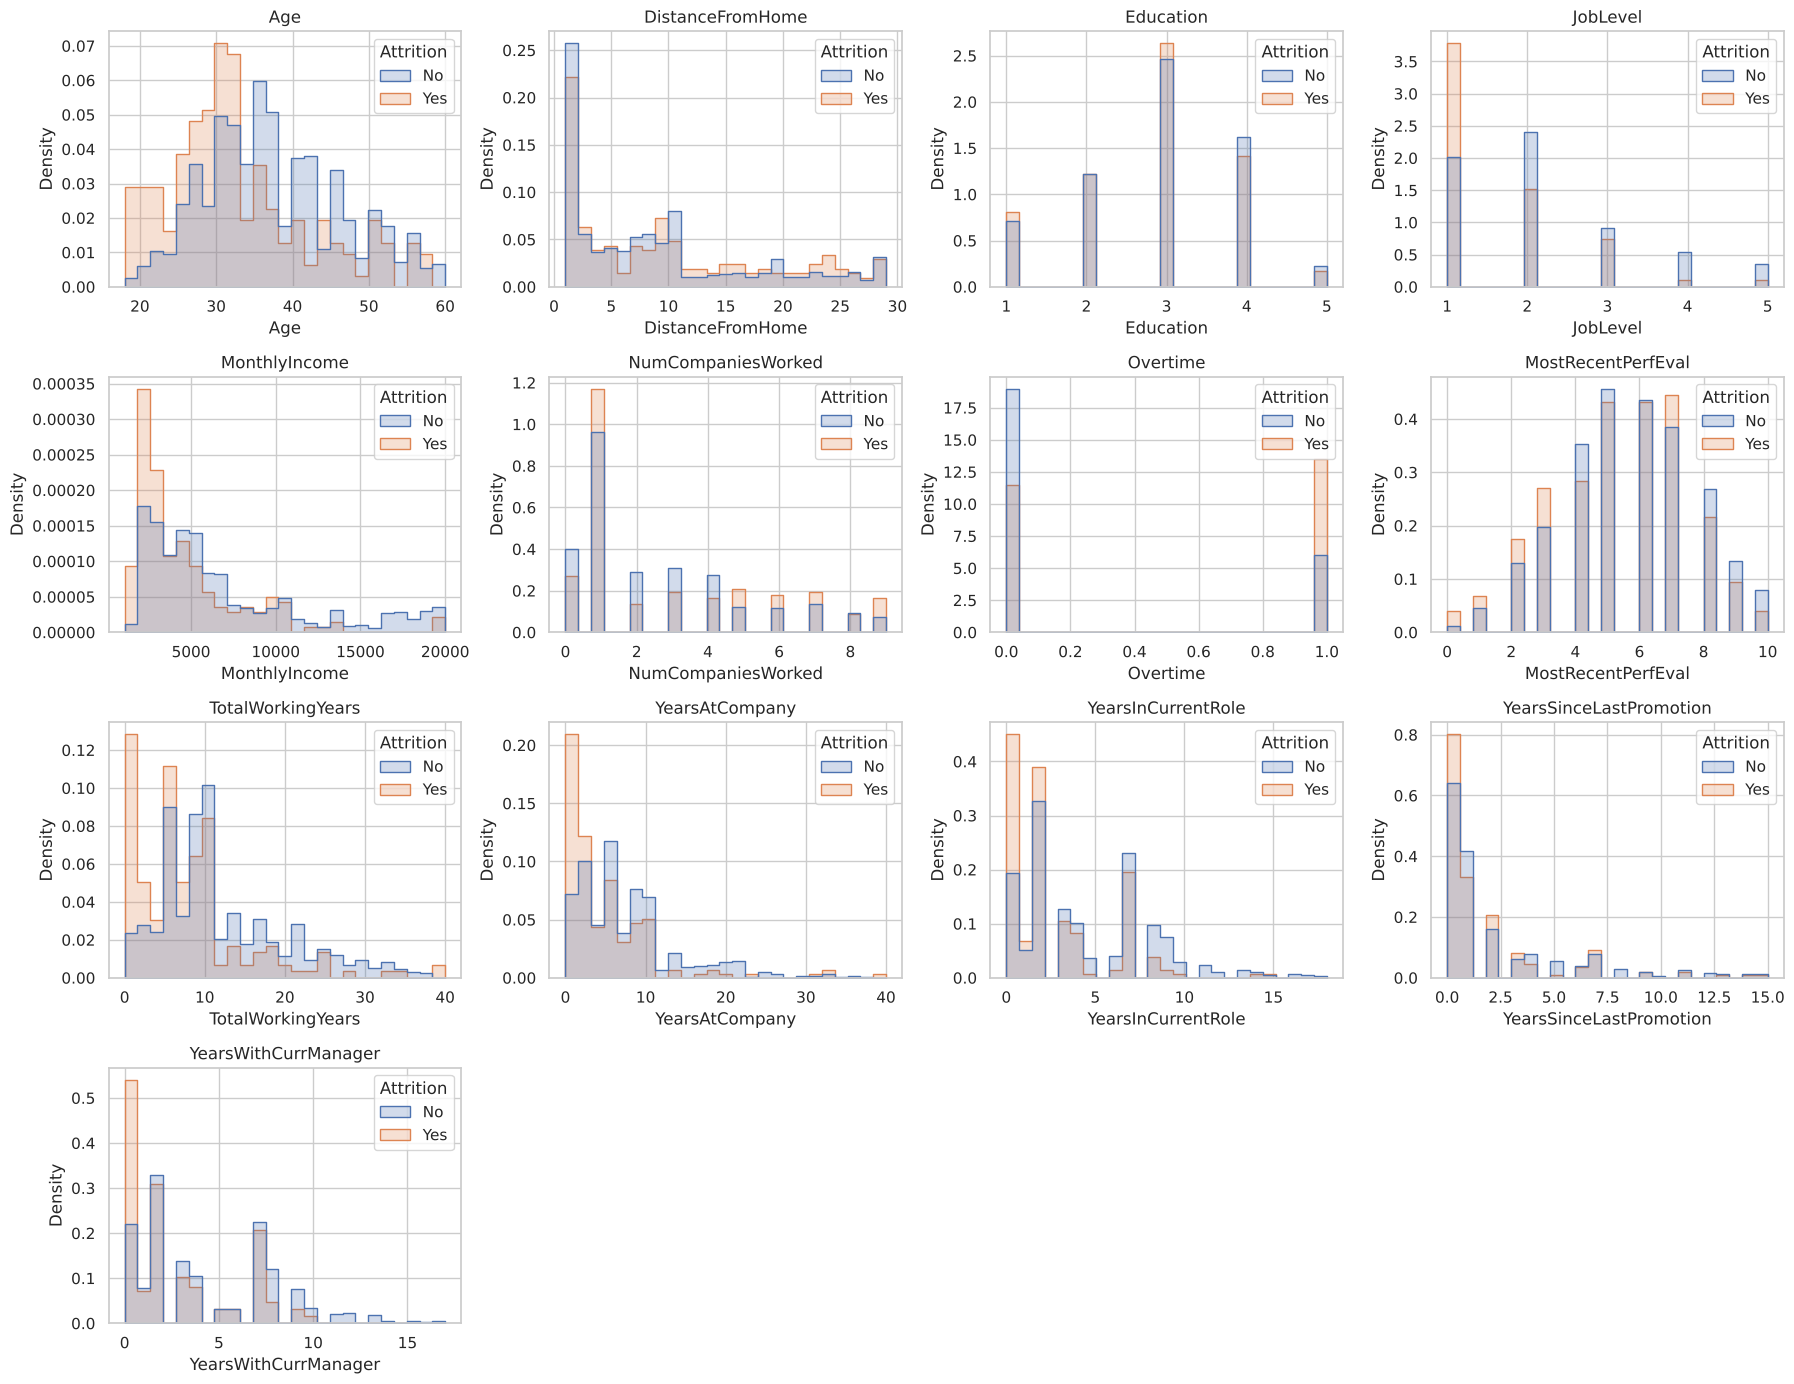

In [11]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=train, x=c, hue="Attrition", bins=25, stat="density", common_norm=False, element="step", ax=ax)
    ax.set_title(c)
for ax in axes.ravel()[len(num_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [12]:
skew = train[num_cols].skew().sort_values(ascending=False)
skew.round(2)

YearsSinceLastPromotion    1.97
YearsAtCompany             1.78
MonthlyIncome              1.36
TotalWorkingYears          1.12
JobLevel                   1.02
NumCompaniesWorked         1.02
DistanceFromHome           1.00
Overtime                   0.94
YearsInCurrentRole         0.87
YearsWithCurrManager       0.76
Age                        0.41
MostRecentPerfEval        -0.11
Education                 -0.25
dtype: float64

### Univariate signal
Univariate AUC computed on training data only (0.5 = no signal). Direction is folded so 0.5 is the floor.

In [13]:
def auc_score(y, s):
    # rank-based (Mann-Whitney) AUC, handles ties via average ranks
    r = pd.Series(s).rank().to_numpy()
    y = np.asarray(y)
    n1, n0 = y.sum(), (1 - y).sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

uni = pd.DataFrame({
    "auc": {c: auc_score(train["y"], train[c]) for c in num_cols},
    "corr_with_y": {c: train[c].corr(train["y"]) for c in num_cols},
})
uni["auc_folded"] = np.maximum(uni["auc"], 1 - uni["auc"])
uni.sort_values("auc_folded", ascending=False).round(3)

,auc,corr_with_y,auc_folded
TotalWorkingYears,0.319,-0.193,0.681
YearsAtCompany,0.332,-0.153,0.668
MonthlyIncome,0.334,-0.178,0.666
YearsInCurrentRole,0.337,-0.191,0.663
Age,0.344,-0.184,0.656
JobLevel,0.346,-0.187,0.654
YearsWithCurrManager,0.348,-0.180,0.652
Overtime,0.650,0.242,0.650
YearsSinceLastPromotion,0.445,-0.067,0.555
DistanceFromHome,0.539,0.053,0.539


### Correlation and multicollinearity
`MonthlyIncome` and `JobLevel` are nearly redundant, and tenure variables move together. This matters for linear models (coefficient instability) but not much for trees.

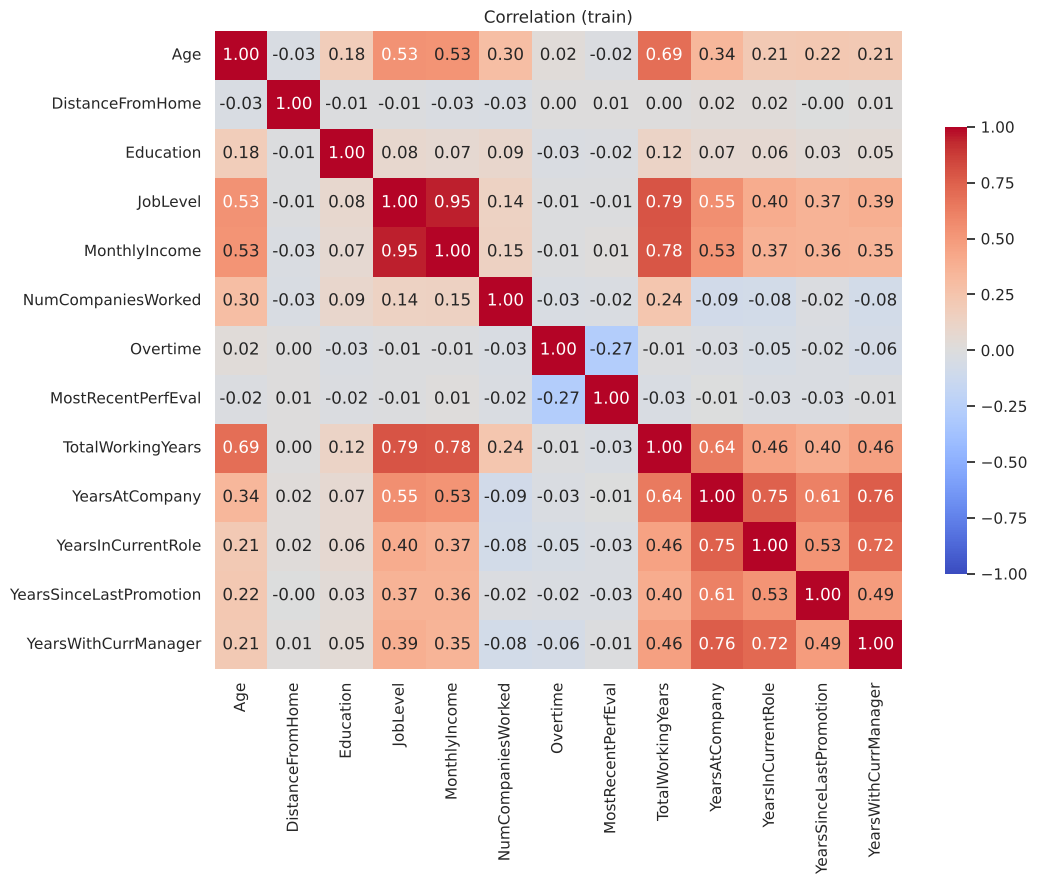

,a,b,corr
43,JobLevel,MonthlyIncome,0.95
47,JobLevel,TotalWorkingYears,0.79
60,MonthlyIncome,TotalWorkingYears,0.78
129,YearsAtCompany,YearsWithCurrManager,0.76
127,YearsAtCompany,YearsInCurrentRole,0.75
142,YearsInCurrentRole,YearsWithCurrManager,0.72
8,Age,TotalWorkingYears,0.69
113,TotalWorkingYears,YearsAtCompany,0.64
128,YearsAtCompany,YearsSinceLastPromotion,0.61


In [14]:
corr = train[num_cols].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": .7})
plt.title("Correlation (train)")
plt.tight_layout()
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
             .rename("corr").reset_index())
pairs.columns = ["a", "b", "corr"]
pairs.loc[pairs["corr"].abs() > 0.6].sort_values("corr", key=abs, ascending=False).round(2)

## 5. Categorical features

In [15]:
def rate_table(col):
    t = train.groupby(col)["y"].agg(n="size", quit_rate="mean").sort_values("quit_rate", ascending=False)
    t["lift_vs_base"] = t["quit_rate"] / train["y"].mean()
    return t.round(3)

for c in cat_cols + ["Overtime", "JobLevel", "Education"]:
    print(f"--- {c}")
    display(rate_table(c))

--- BusinessTravel


,n,quit_rate,lift_vs_base
BusinessTravel,,,
Travel_Frequently,220,0.250,1.581
Travel_Rarely,830,0.147,0.930
Non-Travel,120,0.067,0.422


--- Department


,n,quit_rate,lift_vs_base
Department,,,
Sales,351,0.205,1.297
Human Resources,50,0.200,1.265
Research & Development,769,0.134,0.847


--- Gender


...

,n,quit_rate,lift_vs_base
Overtime,,,
1,337,0.297,1.877
0,833,0.102,0.645


--- JobLevel


,n,quit_rate,lift_vs_base
JobLevel,,,
1,430,0.260,1.647
3,167,0.132,0.833
2,424,0.106,0.671
5,60,0.050,0.316
4,89,0.034,0.213


--- Education


,n,quit_rate,lift_vs_base
Education,,,
1,136,0.176,1.116
3,467,0.167,1.056
2,228,0.158,0.999
4,298,0.141,0.891
5,41,0.122,0.771


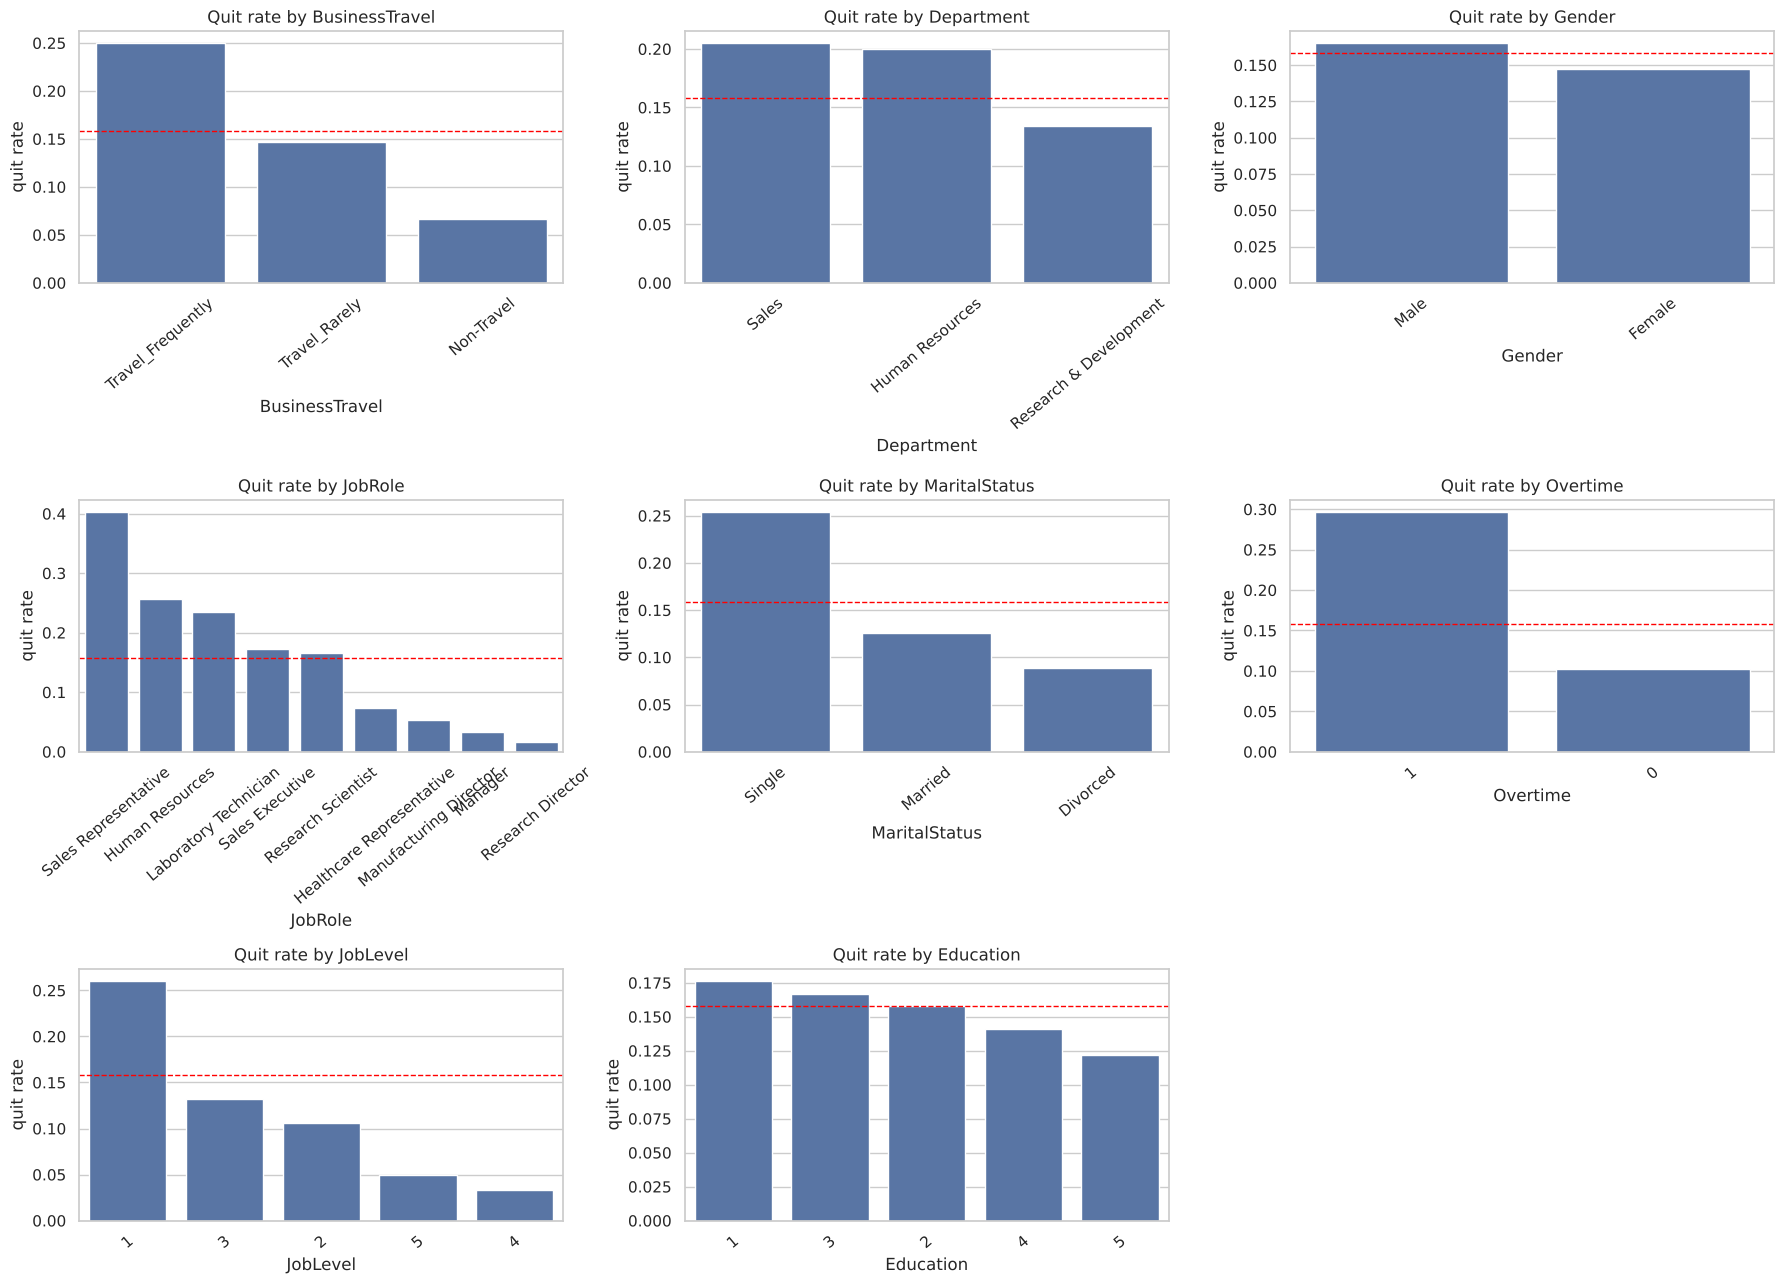

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
plot_cols = cat_cols + ["Overtime", "JobLevel", "Education"]
base = train["y"].mean()
for ax, c in zip(axes.ravel(), plot_cols):
    t = train.groupby(c)["y"].mean().sort_values(ascending=False)
    sns.barplot(x=t.index.astype(str), y=t.values, ax=ax, color="#4C72B0")
    ax.axhline(base, color="red", ls="--", lw=1)
    ax.set_title(f"Quit rate by {c}")
    ax.set_ylabel("quit rate")
    ax.tick_params(axis="x", rotation=40)
for ax in axes.ravel()[len(plot_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Non-linear patterns in ordinal and count variables
Performance eval, number of companies worked, and years since promotion may not be monotonic.

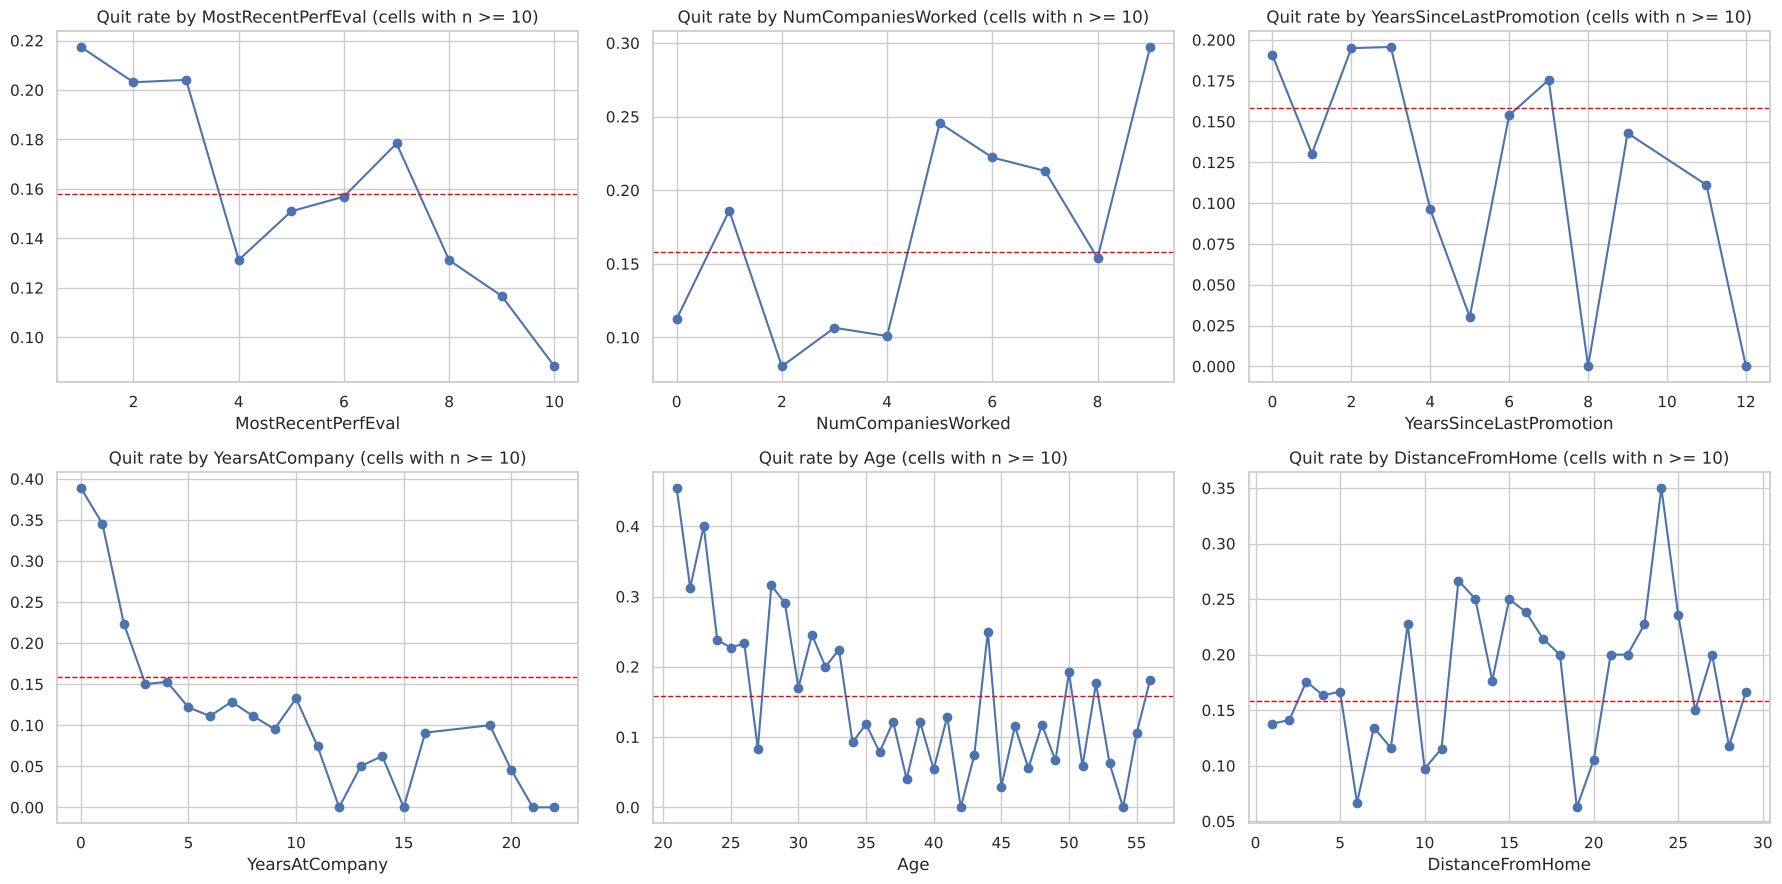

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, c in zip(axes.ravel(), ["MostRecentPerfEval", "NumCompaniesWorked", "YearsSinceLastPromotion",
                                 "YearsAtCompany", "Age", "DistanceFromHome"]):
    g = train.groupby(c)["y"].agg(["mean", "size"])
    g = g[g["size"] >= 10]            # hide tiny cells
    ax.plot(g.index, g["mean"], marker="o")
    ax.axhline(base, color="red", ls="--", lw=1)
    ax.set_title(f"Quit rate by {c} (cells with n >= 10)")
    ax.set_xlabel(c)
plt.tight_layout()
plt.show()

In [18]:
# Binned views for continuous variables
def binned(col, q=8):
    b = pd.qcut(train[col], q=q, duplicates="drop")
    return train.groupby(b, observed=True)["y"].agg(n="size", quit_rate="mean").round(3)

for c in ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "DistanceFromHome"]:
    print(f"--- {c}")
    display(binned(c))

--- Age


,n,quit_rate
Age,,
"(17.999, 27.0]",167,0.281
"(27.0, 30.0]",140,0.257
"(30.0, 33.0]",156,0.224
"(33.0, 35.0]",124,0.105
"(35.0, 39.0]",175,0.086
"(39.0, 43.0]",133,0.060
"(43.0, 49.0]",134,0.104
"(49.0, 60.0]",141,0.121


--- MonthlyIncome


,n,quit_rate
MonthlyIncome,,
"(1080.999, 2387.25]",147,0.320
"(2387.25, 2935.25]",146,0.260
"(2935.25, 4047.875]",146,0.151
"(4047.875, 4961.5]",146,0.144
"(4961.5, 6133.25]",146,0.123
"(6133.25, 8404.25]",146,0.089
"(8404.25, 13347.125]",146,0.144
"(13347.125, 19999.0]",147,0.034


--- TotalWorkingYears


,n,quit_rate
TotalWorkingYears,,
"(-0.001, 4.0]",181,0.343
"(4.0, 6.0]",175,0.189
"(6.0, 8.0]",146,0.178
"(8.0, 10.0]",232,0.116
"(10.0, 15.0]",151,0.099
"(15.0, 21.0]",140,0.086
"(21.0, 40.0]",145,0.069


--- YearsAtCompany


,n,quit_rate
YearsAtCompany,,
"(-0.001, 1.0]",175,0.354
"(1.0, 3.0]",194,0.186
"(3.0, 4.0]",85,0.153
"(4.0, 5.0]",148,0.122
"(5.0, 7.0]",133,0.120
"(7.0, 10.0]",233,0.116
"(10.0, 13.0]",57,0.053
"(13.0, 40.0]",145,0.069


--- DistanceFromHome


,n,quit_rate
DistanceFromHome,,
"(0.999, 2.0]",330,0.139
"(2.0, 4.0]",123,0.171
"(4.0, 7.0]",166,0.127
"(7.0, 9.0]",135,0.170
"(9.0, 13.0]",129,0.140
"(13.0, 21.0]",142,0.183
"(21.0, 29.0]",145,0.207


## 6. Interactions worth testing

In [19]:
# Overtime x JobLevel, MaritalStatus x Overtime, BusinessTravel x Overtime
for a, b in [("Overtime", "JobLevel"), ("MaritalStatus", "Overtime"), ("BusinessTravel", "Overtime")]:
    t = train.pivot_table(index=a, columns=b, values="y", aggfunc="mean").round(3)
    n = train.pivot_table(index=a, columns=b, values="y", aggfunc="size")
    print(f"--- quit rate: {a} x {b}")
    display(t)
    print("counts"); display(n)

--- quit rate: Overtime x JobLevel


JobLevel,1,2,3,4,5
Overtime,,,,,
0,0.152,0.078,0.103,0.032,0.022
1,0.516,0.179,0.196,0.037,0.143


counts


JobLevel,1,2,3,4,5
Overtime,,,,,
0,302,307,116,62,46
1,128,117,51,27,14


--- quit rate: MaritalStatus x Overtime


...

Overtime,0,1
MaritalStatus,,
Divorced,181,77
Married,387,155
Single,265,105


--- quit rate: BusinessTravel x Overtime


Overtime,0,1
BusinessTravel,,
Non-Travel,0.043,0.148
Travel_Frequently,0.179,0.387
Travel_Rarely,0.092,0.285


counts


Overtime,0,1
BusinessTravel,,
Non-Travel,93,27
Travel_Frequently,145,75
Travel_Rarely,595,235


In [20]:
# Income relative to peers at the same job level: is a low-paid employee within a level more likely to leave?
lvl_med = train.groupby("JobLevel")["MonthlyIncome"].transform("median")
train["_inc_vs_level"] = train["MonthlyIncome"] / lvl_med
print("AUC MonthlyIncome         :", round(auc_score(train["y"], train["MonthlyIncome"]), 3))
print("AUC income / level median :", round(auc_score(train["y"], train["_inc_vs_level"]), 3))
train.drop(columns="_inc_vs_level", inplace=True)

AUC MonthlyIncome         : 0.334
AUC income / level median : 0.449


## 7. Cleaning and feature engineering plan
Fit-free transformations only (no statistics learned from data), so the same function is safe to apply to train and test. Anything that needs learned statistics (scaling, target encoding) must be fit inside CV folds later.

In [21]:
def engineer(d: pd.DataFrame) -> pd.DataFrame:
    x = d.copy()

    # --- tenure and career ratios (denominators guarded with +1)
    x["TenureRatio"]        = x["YearsAtCompany"] / (x["TotalWorkingYears"] + 1)      # loyalty share of career
    x["RoleRatio"]          = x["YearsInCurrentRole"] / (x["YearsAtCompany"] + 1)
    x["MgrRatio"]           = x["YearsWithCurrManager"] / (x["YearsAtCompany"] + 1)
    x["PromoGap"]           = x["YearsSinceLastPromotion"] / (x["YearsAtCompany"] + 1)
    x["StagnationYears"]    = x["YearsAtCompany"] - x["YearsSinceLastPromotion"]
    x["AvgYearsPerCompany"] = x["TotalWorkingYears"] / (x["NumCompaniesWorked"] + 1)  # job hopping rate
    x["JobHopper"]          = (x["NumCompaniesWorked"] >= 5).astype(int)
    x["EarlyCareer"]        = (x["TotalWorkingYears"] <= 3).astype(int)
    x["NewHire"]            = (x["YearsAtCompany"] <= 2).astype(int)
    x["AgeAtJoin"]          = x["Age"] - x["YearsAtCompany"]

    # --- pay
    x["LogIncome"]          = np.log1p(x["MonthlyIncome"])
    x["IncomePerLevel"]     = x["MonthlyIncome"] / x["JobLevel"]
    x["IncomePerYearWork"]  = x["MonthlyIncome"] / (x["TotalWorkingYears"] + 1)
    x["IncomePerAge"]       = x["MonthlyIncome"] / x["Age"]

    # --- workload and context
    x["OT_x_Travel"]        = x["Overtime"] * (x["BusinessTravel"] == "Travel_Frequently").astype(int)
    x["OT_x_Single"]        = x["Overtime"] * (x["MaritalStatus"] == "Single").astype(int)
    x["FarFromHome"]        = (x["DistanceFromHome"] >= 20).astype(int)
    x["LowPerf"]            = (x["MostRecentPerfEval"] <= 3).astype(int)

    # --- categorical encodings (deterministic, no leakage)
    x["TravelOrd"]          = x["BusinessTravel"].map({"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})
    x["Male"]               = (x["Gender"] == "Male").astype(int)
    return x

fe = engineer(df)
new_cols = [c for c in fe.columns if c not in df.columns]
print(len(new_cols), "new features:", new_cols)

20 new features: ['TenureRatio', 'RoleRatio', 'MgrRatio', 'PromoGap', 'StagnationYears', 'AvgYearsPerCompany', 'JobHopper', 'EarlyCareer', 'NewHire', 'AgeAtJoin', 'LogIncome', 'IncomePerLevel', 'IncomePerYearWork', 'IncomePerAge', 'OT_x_Travel', 'OT_x_Single', 'FarFromHome', 'LowPerf', 'TravelOrd', 'Male']


In [22]:
# Does each new feature carry signal on its own? (train only, compare to the best raw feature ~0.68)
fe_train = fe[fe["training"] == 1]
fe_auc = pd.Series({c: auc_score(fe_train["y"], fe_train[c]) for c in new_cols})
out = pd.DataFrame({"auc": fe_auc, "auc_folded": np.maximum(fe_auc, 1 - fe_auc)}).sort_values("auc_folded", ascending=False)
out.round(3)

,auc,auc_folded
AvgYearsPerCompany,0.291,0.709
LogIncome,0.334,0.666
StagnationYears,0.336,0.664
NewHire,0.630,0.630
RoleRatio,0.375,0.625
IncomePerAge,0.379,0.621
OT_x_Single,0.614,0.614
MgrRatio,0.390,0.610
EarlyCareer,0.602,0.602
IncomePerLevel,0.405,0.595


In [23]:
# Model-ready matrix: one-hot nominal columns, keep everything numeric
nominal = ["Department", "JobRole", "MaritalStatus", "BusinessTravel", "Gender"]
X_all = pd.get_dummies(fe.drop(columns=["Attrition"]), columns=nominal, drop_first=False, dtype=int)
feature_cols = [c for c in X_all.columns if c not in ["ID", "training", "y"]]

X_train = X_all.loc[X_all["training"] == 1, feature_cols].reset_index(drop=True)
y_train = X_all.loc[X_all["training"] == 1, "y"].reset_index(drop=True)
X_test  = X_all.loc[X_all["training"] == 0, feature_cols].reset_index(drop=True)
y_test  = X_all.loc[X_all["training"] == 0, "y"].reset_index(drop=True)   # used ONLY for final scoring

print("X_train:", X_train.shape, "| X_test:", X_test.shape, "| features:", len(feature_cols))
print("any NaN/inf:", bool(X_train.isna().any().any() or np.isinf(X_train.to_numpy()).any()))

X_train: (1170, 53) | X_test: (300, 53) | features: 53
any NaN/inf: False


In [ ]:
# Save cleaned, engineered data for the modeling notebooks
out_train = X_train.assign(y=y_train, ID=X_all.loc[X_all["training"] == 1, "ID"].values)
out_test  = X_test.assign(y=y_test,  ID=X_all.loc[X_all["training"] == 0, "ID"].values)
out_train.to_csv("../data/train_features.csv", index=False)
out_test.to_csv("../data/test_features.csv", index=False)
print("saved train_features.csv and test_features.csv")DATA_PATH = "../data/EmployeeAttritionPredictionData.xlsx"

saved train_features.csv and test_features.csv


## 8. Findings summary
Based on the cell outputs above.

**Shape and quality**
- 1,470 rows, 21 columns, no missing values, no duplicate rows or IDs. 1,170 train (16% quit), 300 test (17% quit).
- Tenure and age consistency checks show no violations, so no row-level cleaning is needed.
- `MostRecentPerfEval` has 8 rows at 0 although the dictionary says 1 to 10; treat as low performers (do not drop).
- `ID` is an identifier only: drop it from models. `training` is the split flag: never a feature.

**Signal**
- Strongest raw signals are low tenure/experience, low pay and level, young age, working overtime, single status, frequent travel, and roles such as Sales Representative, Laboratory Technician and Human Resources.
- Demographic and weak variables (`Gender`, `Education`, `DistanceFromHome`, `NumCompaniesWorked`, `MostRecentPerfEval`) are near 0.5 AUC alone; keep them for tree models, regularize in linear ones.
- Univariate AUCs top out near 0.68 for raw features (TotalWorkingYears) and 0.71 for the engineered `AvgYearsPerCompany`, so expect a good model to land around 0.75 to 0.85 and gains to come from combining features, not from any single one.

**Cleaning and engineering**
- `MonthlyIncome` and `JobLevel` are about 0.95 correlated; tenure variables are 0.6 to 0.8 correlated. Use regularization (L1/L2) or trees; standardize for linear models inside CV.
- `MonthlyIncome` and tenure variables are right-skewed: use `LogIncome` for linear models.
- Engineered features: tenure and promotion ratios, job-hopping rate, pay relative to level and experience, overtime interactions. Check which add CV AUC before keeping.
- Transformations here are fit-free, so they are safe to apply to train and test identically.

**Next notebook (02_modeling)**
1. Stratified repeated K-fold CV on the training set only (AUC).
2. Models: logistic (L1/L2), random forest, gradient boosting; compare raw vs engineered features.
3. Blend the best models (average of ranks), then score the 300 test rows once.